Архітектура моделі:
Sequential(
  (0): Linear(in_features=10, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=1, bias=True)
)
Epoch [1/50] | Loss: 29630.9764
Epoch [2/50] | Loss: 29560.2040
Epoch [3/50] | Loss: 29408.5949
Epoch [4/50] | Loss: 29065.9595
Epoch [5/50] | Loss: 28414.0984
Epoch [6/50] | Loss: 27155.6744
Epoch [7/50] | Loss: 25132.9192
Epoch [8/50] | Loss: 22015.0634
Epoch [9/50] | Loss: 17972.3812
Epoch [10/50] | Loss: 13096.2278
Epoch [11/50] | Loss: 8701.4710
Epoch [12/50] | Loss: 5965.5011
Epoch [13/50] | Loss: 5017.3152
Epoch [14/50] | Loss: 4626.0734
Epoch [15/50] | Loss: 4263.7527
Epoch [16/50] | Loss: 4134.7441
Epoch [17/50] | Loss: 3944.8508
Epoch [18/50] | Loss: 3810.9569
Epoch [19/50] | Loss: 3811.8576
Epoch [20/50] | Loss: 3690.8950
Epoch [21/50] | Loss: 3582.3986
Epoch [22/50] | Loss

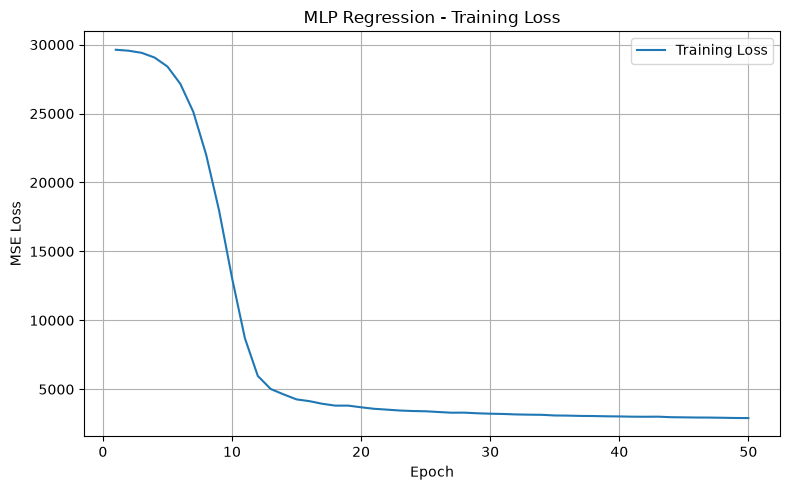

In [2]:

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(
    y_train,
    dtype=torch.float32
).reshape(-1, 1)

y_test = torch.tensor(
    y_test,
    dtype=torch.float32
).reshape(-1, 1)

train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)


input_size = X_train.shape[1]

model = nn.Sequential(

    # Вхідний шар -> перший прихований шар
    nn.Linear(input_size, 64),
    nn.ReLU(),

    # Перший -> другий прихований шар
    nn.Linear(64, 32),
    nn.ReLU(),

    # Другий -> третій прихований шар
    nn.Linear(32, 16),
    nn.ReLU(),

    # Вихідний шар
    nn.Linear(16, 1)
)

print("Архітектура моделі:")
print(model)


# Функція втрат
criterion = nn.MSELoss()

# Оптимізатор Adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Кількість епох
epochs = 50

# Список для збереження помилок
train_losses = []


for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    total = 0

    for inputs, labels in train_loader:

        # Обнуляємо градієнти
        optimizer.zero_grad()

        # Пряме поширення
        outputs = model(inputs)

        # Обчислення MSE
        loss = criterion(outputs, labels)

        # Зворотне поширення
        loss.backward()

        # Оновлення ваг
        optimizer.step()

        # Накопичення помилки
        running_loss += loss.item() * inputs.size(0)
        total += inputs.size(0)

    # Середня помилка за епоху
    epoch_loss = running_loss / total

    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"| Loss: {epoch_loss:.4f}"
    )



model.eval()

with torch.no_grad():

    test_outputs = model(X_test)

    test_loss = criterion(test_outputs, y_test).item()

print("\n========== РЕЗУЛЬТАТИ ==========")

print(f"Останній Training Loss: {train_losses[-1]:.4f}")
print(f"Test MSE: {test_loss:.4f}")


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.title("MLP Regression - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid()

plt.tight_layout()

plt.savefig(
    "mlp_regression_loss.png",
    dpi=300,
    bbox_inches="tight"
    
)

plt.show()
